# 03 – Random Forest Regressor (Baseline ML)

**Ziel:** Random Forest als erstes ML-Modell auf NASA CMAPSS FD003.  
Ergebnis wird direkt mit den Statistik-Modellen aus R verglichen.

**Baseline aus Statistik-Teil (R):**
- Cox PH statisch:      C-Index = 0.756
- Cox PH zeitabhängig:  C-Index = 0.986 (In-Sample, nicht CV)

**Daten:** Aus `data/processed/train.csv` und `test.csv` (aufbereitet in R)

> **Reproduzierbarkeit:** Originallauf (Juni 2026, Windows): RMSE 20.72, NASA 2051. Neulauf auf macOS (Oktober 2026, gleiche Paketversionen): RMSE 20.66, NASA 2012.  
> Die Abweichung entsteht durch Fließkomma-Unterschiede zwischen Plattformen; die Grid Search wählt bei fast gleichem CV-Wert eine andere Konfiguration. README und Vergleich nennen die Werte des Originallaufs
> (`ml/reports/model_results_original.json`); die Ausgaben unten zeigen den Neulauf.

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_val_score

from src.data.loader import load_train, load_test, get_feature_cols
from src.evaluation.metrics import evaluate_all, compare_models
from src.config import RF_PARAMS, REPORTS

sns.set_theme(style='whitegrid')
REPORTS.mkdir(parents=True, exist_ok=True)
print('Setup fertig.')

Setup fertig.


## 1. Daten laden

In [2]:
train = load_train()
test  = load_test()

# Feature-Set: rohe Sensoren + Rolling Mean/Std (window=5, aus R)
feature_cols = get_feature_cols('raw+rolling')

X_train = train[feature_cols]
y_train = train['RUL']
groups  = train['unit_number']   # für GroupKFold

X_test  = test[feature_cols]
y_test  = test['RUL_true']

print(f'Train: {X_train.shape}  |  Test: {X_test.shape}')
print(f'Features: {feature_cols[:6]} ... ({len(feature_cols)} total)')

Train geladen: 24320 Zeilen (400 Rolling-NAs entfernt)
Test geladen: 100 Zeilen (eine pro Engine)
Train: (24320, 36)  |  Test: (100, 36)
Features: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_8', 'sensor_10'] ... (36 total)


## 2. Baseline Random Forest

Erst schnell schauen was Default-Hyperparameter liefern,  
bevor wir Zeit in Grid Search investieren.

In [3]:
rf_baseline = RandomForestRegressor(**RF_PARAMS)
rf_baseline.fit(X_train, y_train)

y_pred_baseline = rf_baseline.predict(X_test)
results_baseline = evaluate_all(y_test.values, y_pred_baseline, 'RF Baseline')
print(results_baseline)

{'Model': 'RF Baseline', 'RMSE': 20.96, 'MAE': 15.12, 'R²': 0.744, 'NASA Score': 2047.5}


## 3. Cross-Validation mit GroupKFold

**Warum GroupKFold statt Standard-CV?**  
Der Datensatz hat 24.720 Zeilen von 100 Engines — jede Engine hat ~247 Zeilen.  
Standard-CV (zufällige Splits) würde Zeilen derselben Engine in Train *und* Validation stecken.  
Das ist Information Leakage: das Modell hat die Engine quasi schon gesehen.  
GroupKFold garantiert, dass jede Engine komplett entweder in Train oder Validation landet.

In [4]:
gkf = GroupKFold(n_splits=5)

cv_scores = cross_val_score(
    # n_jobs=1 im Modell: parallelisiert wird über die Folds (sonst Überbelegung der Kerne)
    RandomForestRegressor(**(RF_PARAMS | {'n_jobs': 1})),
    X_train, y_train,
    cv=gkf,
    groups=groups,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

print(f'GroupKFold CV RMSE: {-cv_scores.mean():.2f} ± {cv_scores.std():.2f}')
print(f'Fold-Scores:        {[-round(s, 2) for s in cv_scores]}')

GroupKFold CV RMSE: 17.46 ± 1.01
Fold-Scores:        [np.float64(19.02), np.float64(16.84), np.float64(17.43), np.float64(16.03), np.float64(17.97)]


## 4. Hyperparameter-Tuning mit GridSearch

In [5]:
param_grid = {
    'n_estimators':    [200, 500],
    'max_depth':       [10, 20, None],
    'min_samples_leaf':[1, 5, 10],
    'max_features':    ['sqrt', 0.5],
}

grid_rf = GridSearchCV(
    # n_jobs=1 im Modell: GridSearchCV verteilt die 180 Fits auf alle Kerne.
    # Doppelte Parallelisierung (Modell + Grid) überbelegt die CPU und ließ den Lauf hängen.
    RandomForestRegressor(random_state=42, n_jobs=1),
    param_grid,
    cv=GroupKFold(n_splits=5),
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1,
)
grid_rf.fit(X_train, y_train, groups=groups)

print(f'Beste Parameter: {grid_rf.best_params_}')
print(f'Bestes CV-RMSE:  {-grid_rf.best_score_:.2f}')

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Beste Parameter: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 500}
Bestes CV-RMSE:  16.76


## 5. Evaluation auf Test-Set

In [6]:
best_rf = grid_rf.best_estimator_
y_pred_rf = best_rf.predict(X_test)

results_rf = evaluate_all(y_test.values, y_pred_rf, 'Random Forest')
print(pd.DataFrame([results_rf]).set_index('Model').to_string())

                RMSE    MAE     R²  NASA Score
Model                                         
Random Forest  20.66  15.36  0.751      2011.9


## 6. Feature Importance

Direkter Vergleich mit Cox PH Hazard Ratios aus dem Statistik-Teil:  
- Cox HR > 1 (Risikoerhöhung): sensor_2  
- Cox HR < 1 (Risikosenkung): sensor_11, sensor_17, sensor_3


Top-10 Features:
            Feature  Importance
sensor_11_roll_mean    0.176341
 sensor_3_roll_mean    0.113984
sensor_17_roll_mean    0.111216
 sensor_4_roll_mean    0.102161
          sensor_11    0.070484
 sensor_8_roll_mean    0.070025
sensor_14_roll_mean    0.058680
          sensor_14    0.045617
 sensor_2_roll_mean    0.041475
           sensor_8    0.033465


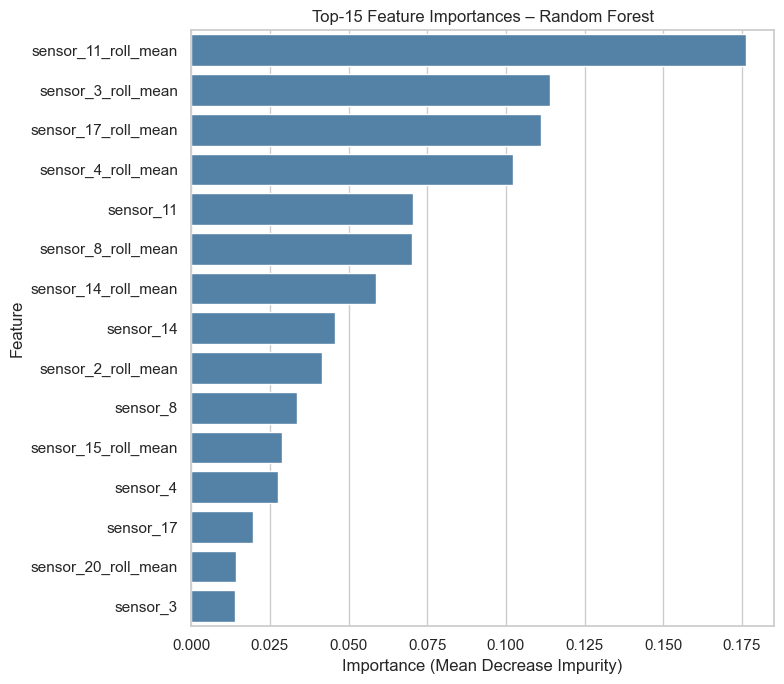

In [7]:
importance_df = pd.DataFrame({
    'Feature':    feature_cols,
    'Importance': best_rf.feature_importances_
}).sort_values('Importance', ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
sns.barplot(
    data=importance_df.head(15),
    x='Importance', y='Feature',
    color='steelblue', ax=ax
)
ax.set_title('Top-15 Feature Importances – Random Forest')
ax.set_xlabel('Importance (Mean Decrease Impurity)')
plt.tight_layout()
plt.savefig(REPORTS / 'rf_feature_importance.png', dpi=150)
plt.show()

print('\nTop-10 Features:')
print(importance_df.head(10).to_string(index=False))

## 7. Predicted vs. Actual

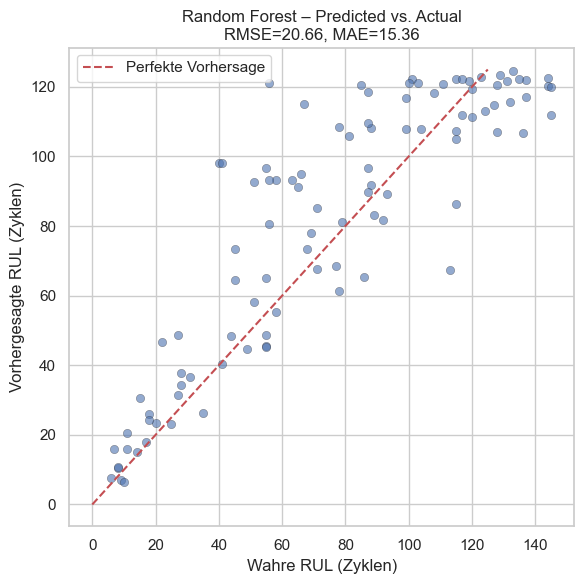

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_pred_rf, alpha=0.6, edgecolors='k', linewidths=0.3)
ax.plot([0, 125], [0, 125], 'r--', label='Perfekte Vorhersage')
ax.set_xlabel('Wahre RUL (Zyklen)')
ax.set_ylabel('Vorhergesagte RUL (Zyklen)')
ax.set_title(f'Random Forest – Predicted vs. Actual\nRMSE={results_rf["RMSE"]}, MAE={results_rf["MAE"]}')
ax.legend()
plt.tight_layout()
plt.savefig(REPORTS / 'rf_predicted_vs_actual.png', dpi=150)
plt.show()

## 8. Ergebnisse speichern (für finalen Vergleich)

In [9]:
from src.evaluation.results import save_results, save_predictions

# Metriken → model_results.json, Vorhersagen pro Engine → predictions_test.csv
save_results(results_rf)
save_predictions('Random Forest', test['unit_number'], y_test, y_pred_rf)

Metriken gespeichert: model_results.json → {'Model': 'Random Forest', 'RMSE': 20.66, 'MAE': 15.36, 'R²': 0.751, 'NASA Score': 2011.9}
Vorhersagen gespeichert: predictions_test.csv (Spalte 'Random Forest')
